# **Lab 7(A) - Laplacian Filter**
**Course:** ARTI403 – Image Processing
**Student:** Mohammed Moayed Alquriniy – 2240007325

The Laplacian is a second‑order derivative operator:

$$\nabla^2 f = \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2} \approx f(x+1,y)+f(x-1,y)+f(x,y+1)+f(x,y-1)-4f(x,y)$$

It responds strongly to rapid intensity changes (edges, fine detail) and is zero in flat regions.
Sharpening is obtained by combining the Laplacian with the original image:

$$g(x,y) = f(x,y) + c\,\nabla^2 f(x,y), \qquad c=-1 \text{ when the kernel centre is negative}$$

In [1]:
import os
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

IMG_DIR = 'images'
OUT_DIR = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)

def save(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=110, bbox_inches='tight')

## Apply Laplacian Filter on Image to get Sharp Image
### Part 1 – Manual 4‑neighbour Laplacian kernel with `cv2.filter2D`

Image shape: (438, 401) | dtype: uint8
Laplacian range: [-123.0, 110.0]


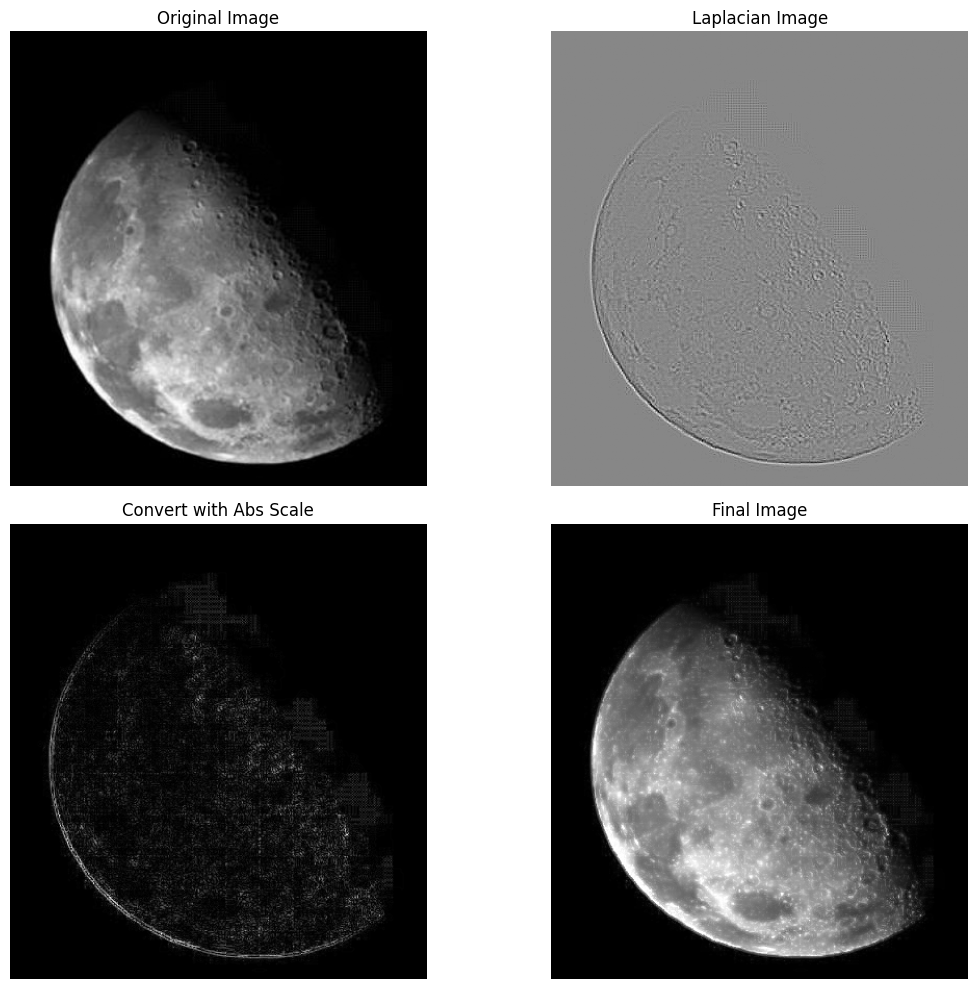

In [2]:
# ================ ( Laplacian Filter ) ===================

# 0. Image file path
imgFile = os.path.join(IMG_DIR, "moon.jpg")

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)
print('Image shape:', img.shape, '| dtype:', img.dtype)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# 3. Apply the filter using filter2D
# Use cv2.CV_64F to keep the negative Laplacian values (no clipping)
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)
print('Laplacian range: [%.1f, %.1f]' % (laplacian_manual.min(), laplacian_manual.max()))

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# 5. Final image (lab version): original + |Laplacian|
#    cv2.add saturates at 255 (plain `img + laplacian_abs` on uint8 wraps around 255 -> 0)
finalImage = cv2.add(img, laplacian_abs)

# 6. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('A1_manual_laplacian.png')
plt.show()

### Part 1b – Why `img + laplacian_abs` must not be done directly on `uint8`
NumPy `uint8` arithmetic is **modular**: `250 + 10 = 4`. Bright pixels on the moon wrap to black.
Below the plain addition is compared with the saturated `cv2.add` and with the **correct** sharpening
formula $g = f - \nabla^2 f$ (the kernel centre is negative, so the Laplacian must be *subtracted*).

Pixels that wrapped around in naive sum: 541


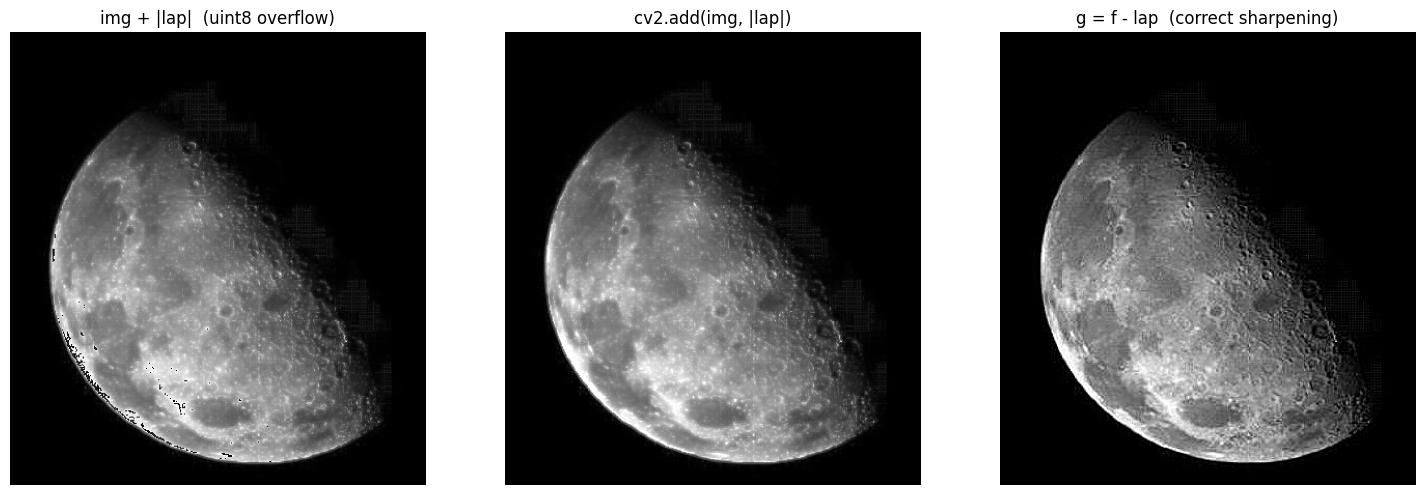

In [3]:
naive_sum   = img + laplacian_abs                       # uint8 overflow (wrap-around)
saturated   = cv2.add(img, laplacian_abs)                 # clipped to 255
sharpened_4 = np.clip(img.astype(np.float64) - laplacian_manual, 0, 255).astype(np.uint8)  # g = f - lap

print('Pixels that wrapped around in naive sum:', int(np.sum(img.astype(int) + laplacian_abs > 255)))

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(naive_sum, cmap='gray'),   plt.title('img + |lap|  (uint8 overflow)')
plt.subplot(132), plt.imshow(saturated, cmap='gray'),   plt.title('cv2.add(img, |lap|)')
plt.subplot(133), plt.imshow(sharpened_4, cmap='gray'), plt.title('g = f - lap  (correct sharpening)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('A2_overflow_vs_correct.png')
plt.show()

### Part 2 – Built‑in `cv2.Laplacian` with Gaussian pre‑smoothing

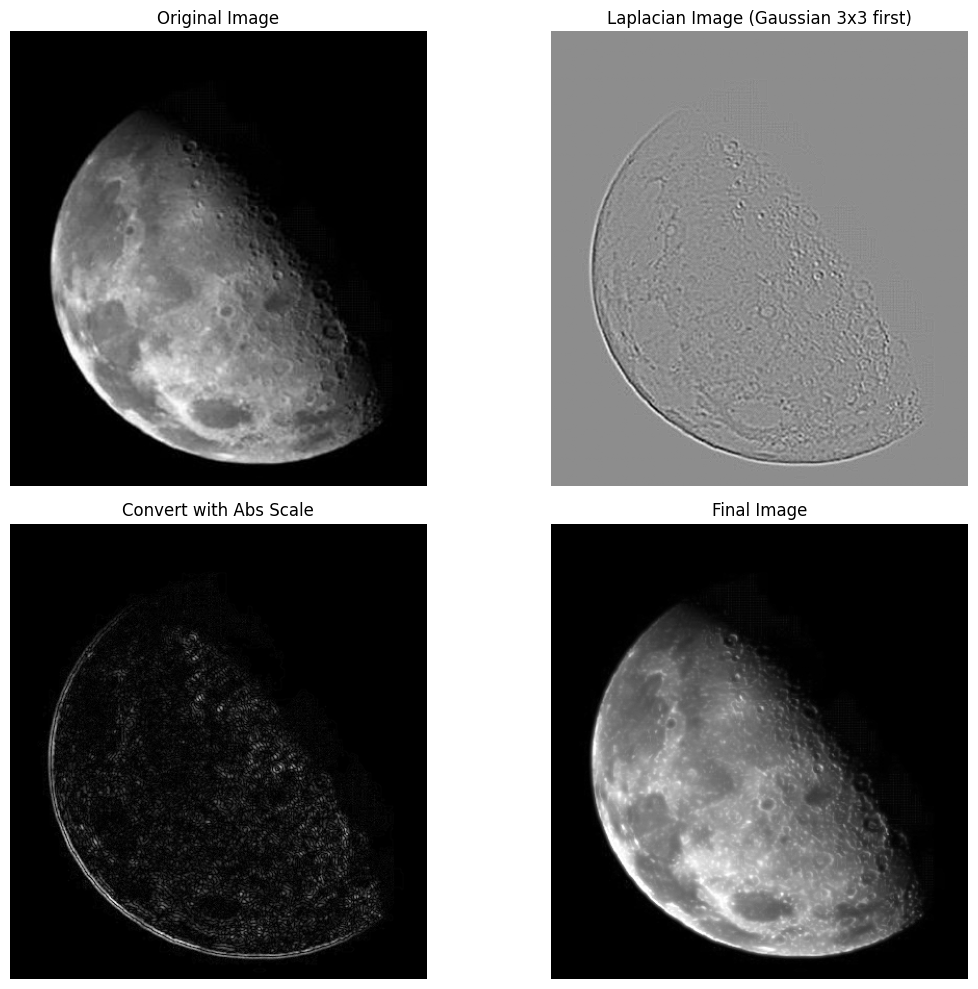

In [4]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and original Image (saturated)
finalImage2 = cv2.add(img, laplacian_8bit)

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image (Gaussian 3x3 first)')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('A3_builtin_laplacian.png')
plt.show()

### Part 3 – 4‑neighbour vs 8‑neighbour (diagonal) kernel

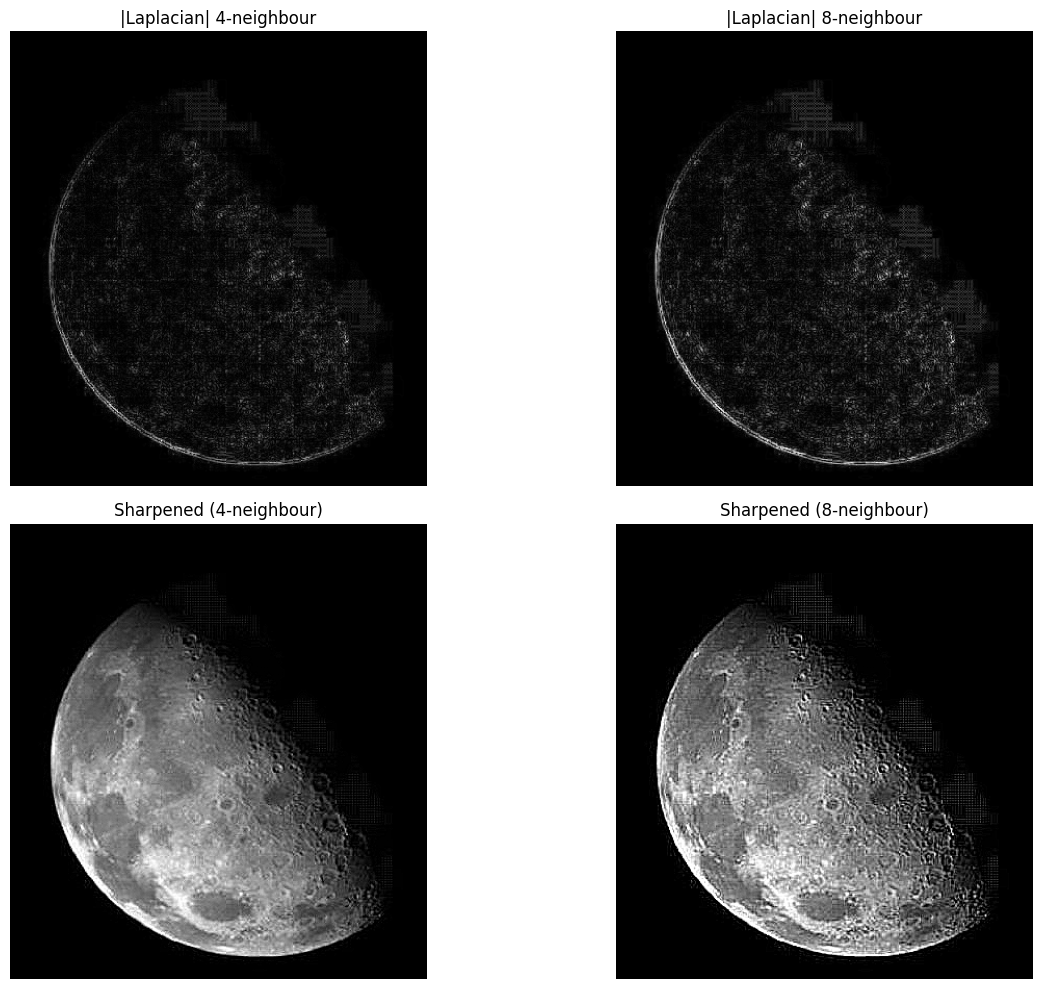

In [5]:
kernel_8 = np.array([
    [1,  1,  1],
    [1, -8,  1],
    [1,  1,  1]
], dtype=np.float32)

lap_8 = cv2.filter2D(img, cv2.CV_64F, kernel_8)
sharpened_8 = np.clip(img.astype(np.float64) - lap_8, 0, 255).astype(np.uint8)

plt.figure(figsize=(14, 10))
plt.subplot(221), plt.imshow(cv2.convertScaleAbs(laplacian_manual), cmap='gray'), plt.title('|Laplacian| 4-neighbour')
plt.subplot(222), plt.imshow(cv2.convertScaleAbs(lap_8), cmap='gray'),            plt.title('|Laplacian| 8-neighbour')
plt.subplot(223), plt.imshow(sharpened_4, cmap='gray'), plt.title('Sharpened (4-neighbour)')
plt.subplot(224), plt.imshow(sharpened_8, cmap='gray'), plt.title('Sharpened (8-neighbour)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('A4_kernel_4_vs_8.png')
plt.show()

### Part 4 – Measuring sharpness
The variance of the Laplacian is a common focus/sharpness measure; a sharper image gives a higher value.

Image                        | Laplacian variance
--------------------------------------------------
Original                     |       76.5
img + |lap| (cv2.add)        |      421.8
Gaussian + Laplacian         |      158.9
f - lap (4-neighbour)        |      869.6
f - lap (8-neighbour)        |     3011.0


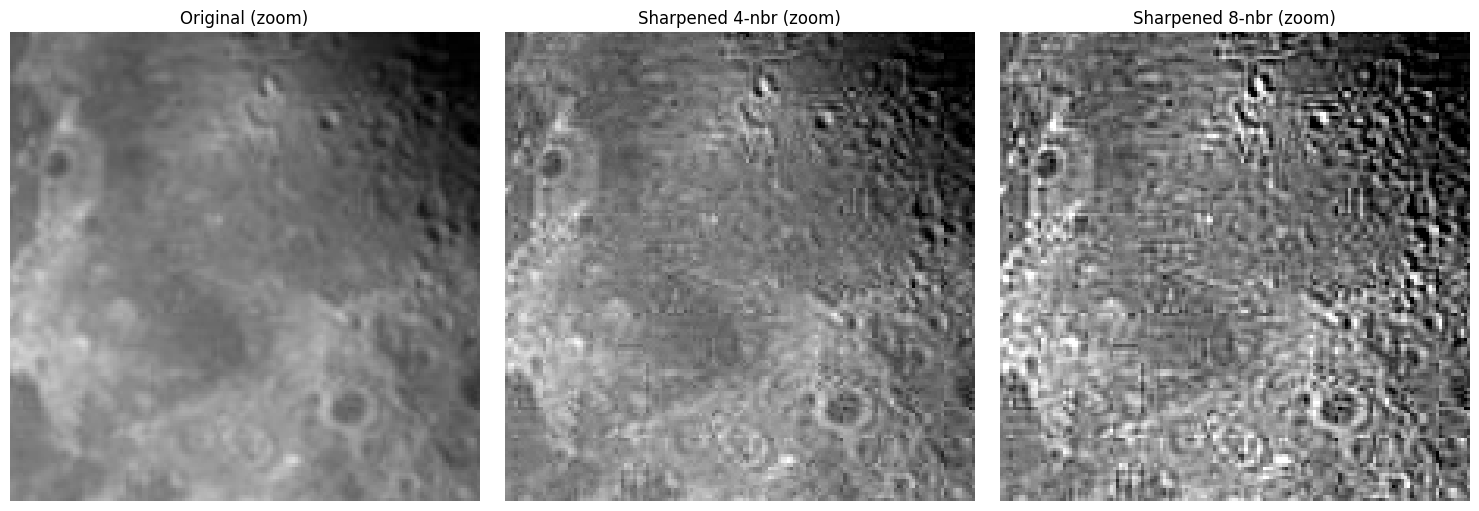

In [6]:
def sharpness(image):
    return cv2.Laplacian(image, cv2.CV_64F).var()

results = {
    'Original':                 img,
    'img + |lap| (cv2.add)':    finalImage,
    'Gaussian + Laplacian':     finalImage2,
    'f - lap (4-neighbour)':    sharpened_4,
    'f - lap (8-neighbour)':    sharpened_8,
}
print(f"{'Image':28s} | Laplacian variance")
print('-' * 50)
for name, im in results.items():
    print(f"{name:28s} | {sharpness(im):10.1f}")

# zoomed crop to see fine crater detail
y0, y1, x0, x1 = 150, 300, 100, 250
plt.figure(figsize=(15, 5))
for i, (name, im) in enumerate([('Original', img), ('Sharpened 4-nbr', sharpened_4), ('Sharpened 8-nbr', sharpened_8)]):
    plt.subplot(1, 3, i + 1), plt.imshow(im[y0:y1, x0:x1], cmap='gray', vmin=0, vmax=255), plt.title(name + ' (zoom)'), plt.axis('off')
plt.tight_layout(); save('A5_zoom.png')
plt.show()

### Part 5 – Laplacian on a noisy image
The Laplacian is a high‑pass filter, so it amplifies noise as well as edges. Sharpening the salt‑and‑pepper image
directly makes the noise worse; removing the noise first with a median filter gives a clean sharp result.

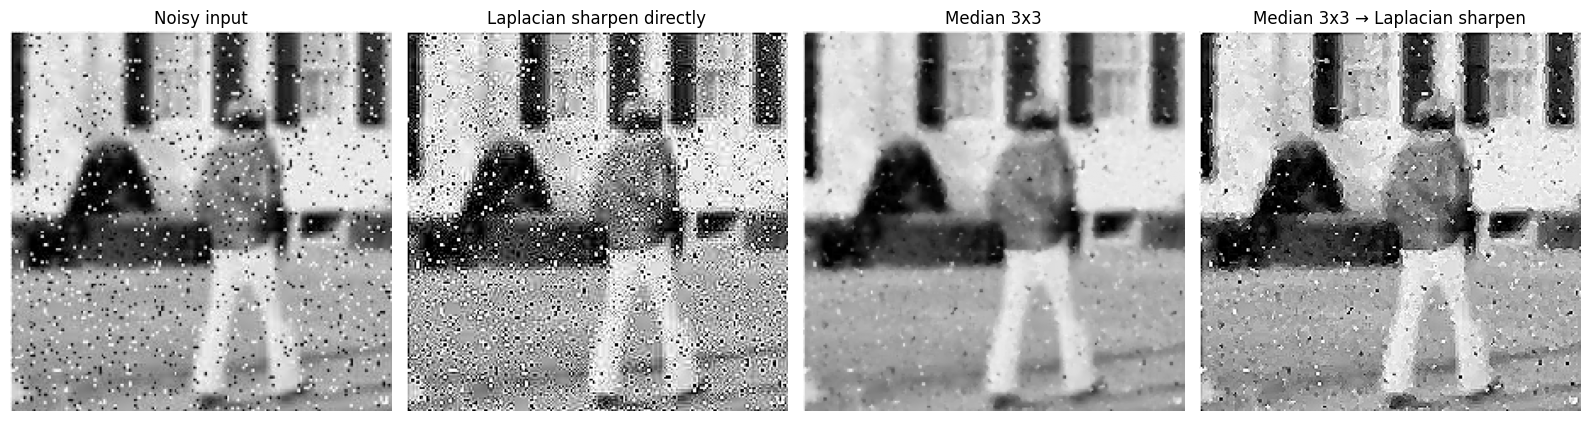

In [7]:
noisy = cv2.imread(os.path.join(IMG_DIR, 'noisy_person.jpg'), 0)

def laplacian_sharpen(image, kernel=manual_kernel):
    lap = cv2.filter2D(image, cv2.CV_64F, kernel)
    return np.clip(image.astype(np.float64) - lap, 0, 255).astype(np.uint8)

direct   = laplacian_sharpen(noisy)
denoised = cv2.medianBlur(noisy, 3)
clean_sh = laplacian_sharpen(denoised)

plt.figure(figsize=(16, 4.5))
plt.subplot(141), plt.imshow(noisy, cmap='gray'),    plt.title('Noisy input')
plt.subplot(142), plt.imshow(direct, cmap='gray'),   plt.title('Laplacian sharpen directly')
plt.subplot(143), plt.imshow(denoised, cmap='gray'), plt.title('Median 3x3')
plt.subplot(144), plt.imshow(clean_sh, cmap='gray'), plt.title('Median 3x3 → Laplacian sharpen')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout(); save('A6_noisy_sharpen.png')
plt.show()